In [12]:
from pathlib import Path

import pandas as pd
import numpy as np
import joblib

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [13]:
PROJECT_ROOT = Path("..")

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "windfarmA_features.csv"
)

df = pd.read_csv(DATA_PATH)

print(df.shape)

(49851, 187)


In [14]:
MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "isolation_forest.pkl"
)

model = joblib.load(MODEL_PATH)

In [15]:
X = df.drop(
    columns=["event_id", "label", "target"]
)

y = df["target"]

In [16]:
pred = model.predict(X)

pred = np.where(
    pred == -1,
    1,
    0
)

In [17]:
print(
    classification_report(
        y,
        pred
    )
)

              precision    recall  f1-score   support

           0       0.51      0.50      0.50     25051
           1       0.50      0.51      0.51     24800

    accuracy                           0.51     49851
   macro avg       0.51      0.51      0.51     49851
weighted avg       0.51      0.51      0.51     49851



In [18]:
cm = confusion_matrix(
    y,
    pred
)

print(cm)

[[12526 12525]
 [12117 12683]]


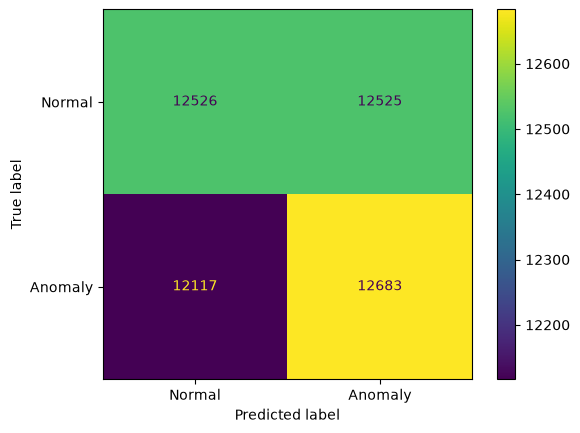

In [19]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
).plot()

plt.show()

In [20]:
total_anomalies = (y == 1).sum()

detected_anomalies = (
    (y == 1) &
    (pred == 1)
).sum()

detection_rate = (
    detected_anomalies
    / total_anomalies
)

print(
    f"Detection Rate: {detection_rate:.2%}"
)

Detection Rate: 51.14%


In [21]:
false_alarms = (
    (y == 0) &
    (pred == 1)
).sum()

normal_samples = (
    y == 0
).sum()

false_alarm_rate = (
    false_alarms
    / normal_samples
)

print(
    f"False Alarm Rate: {false_alarm_rate:.2%}"
)

False Alarm Rate: 50.00%
